In [1]:
import sys
import platform
import importlib.metadata as metadata

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Architecture:", platform.machine())

for package in [
    "tensorflow",
    "tensorflow-macos",
    "tensorflow-metal",
    "keras",
    "numpy",
    "protobuf"
]:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, "kurulu değil")

Python: 3.11.15 (main, Mar 11 2026, 17:14:47) [Clang 20.1.8 ]
Platform: macOS-15.6-arm64-arm-64bit
Architecture: arm64
tensorflow 2.21.0
tensorflow-macos kurulu değil
tensorflow-metal kurulu değil
keras 3.14.0
numpy 2.4.4
protobuf 7.34.1


In [2]:
import os
import glob
import re
import sys
import random

import cv2
import numpy as np
import tensorflow as tf
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils import to_categorical
from keras.metrics import MeanIoU

from simple_unet import enhanced_unet, combined_loss

np.set_printoptions(threshold=sys.maxsize)

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

SIZE_X = 496
SIZE_Y = 496

class_names = {
    0: 'BACKGROUND',
    1: 'VITREUS',
    2: 'RNFL',
    3: 'GCL',
    4: 'IPL',
    5: 'INL',
    6: 'OPL',
    7: 'ONL',
    8: 'ELM',
    9: 'EZ',
    10: 'IZ',
    11: 'RPE',
    12: 'CHORIOCAPILLARIS',
}

n_classes = len(class_names)

TRAIN_PATH_X = 'cropped_output'
TRAIN_PATH_Y = 'maskedoutputs'


def get_idx(path):
    match = re.search(r'_(\d+)\.png$', os.path.basename(path))
    if match is None:
        raise ValueError(f'Cannot extract index from: {path}')
    return int(match.group(1))


all_X = glob.glob(os.path.join(TRAIN_PATH_X, 'output_normal_*.png'))
all_Y = glob.glob(os.path.join(TRAIN_PATH_Y, 'output_normal_*.png'))

idx_X = {get_idx(path) for path in all_X}
idx_Y = {get_idx(path) for path in all_Y}
common = idx_X & idx_Y

matched_X = [path for path in all_X if get_idx(path) in common]
matched_Y = [path for path in all_Y if get_idx(path) in common]

matched_X.sort(key=get_idx)
matched_Y.sort(key=get_idx)

TRAIN_PATH_X = matched_X
TRAIN_PATH_Y = matched_Y

print(f'Matched pairs: {len(TRAIN_PATH_X)}')
print('First 5 image files:', TRAIN_PATH_X[:5])
print('First 5 mask files:', TRAIN_PATH_Y[:5])


Matched pairs: 50
First 5 image files: ['cropped_output/output_normal_1.png', 'cropped_output/output_normal_2.png', 'cropped_output/output_normal_3.png', 'cropped_output/output_normal_4.png', 'cropped_output/output_normal_5.png']
First 5 mask files: ['maskedoutputs/output_normal_1.png', 'maskedoutputs/output_normal_2.png', 'maskedoutputs/output_normal_3.png', 'maskedoutputs/output_normal_4.png', 'maskedoutputs/output_normal_5.png']


In [3]:
from tensorflow.keras import mixed_precision

if tf.config.list_physical_devices('GPU'):
    mixed_precision.set_global_policy('mixed_float16')
else:
    mixed_precision.set_global_policy('float32')

print('Policy:', mixed_precision.global_policy())


Policy: <DTypePolicy "float32">


In [4]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))


[]


In [5]:
train_images = []

for img_path in TRAIN_PATH_X:
    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise FileNotFoundError(f'Image not found: {img_path}')

    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    if img.shape[:2] != (SIZE_X, SIZE_Y):
        img = cv2.resize(img, (SIZE_Y, SIZE_X), interpolation=cv2.INTER_AREA)

    train_images.append(img)

train_images = np.array(train_images)
print('train_images shape:', train_images.shape)
print('dtype:', train_images.dtype, 'min:', train_images.min(), 'max:', train_images.max())


train_images shape: (50, 496, 496)
dtype: uint8 min: 0 max: 255


In [6]:
train_masks = []

for mask_path in TRAIN_PATH_Y:
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f'Mask not found: {mask_path}')

    if mask.shape[:2] != (SIZE_X, SIZE_Y):
        mask = cv2.resize(mask, (SIZE_Y, SIZE_X), interpolation=cv2.INTER_NEAREST)

    train_masks.append(mask.astype(np.uint8))

train_masks = np.array(train_masks, dtype=np.uint8)
unique_labels = np.unique(train_masks)

print('train_masks shape:', train_masks.shape)
print('Unique labels in masks:', unique_labels)

assert unique_labels.min() >= 0
assert unique_labels.max() < n_classes, f'Mask label {unique_labels.max()} exceeds n_classes - 1'


train_masks shape: (50, 496, 496)
Unique labels in masks: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


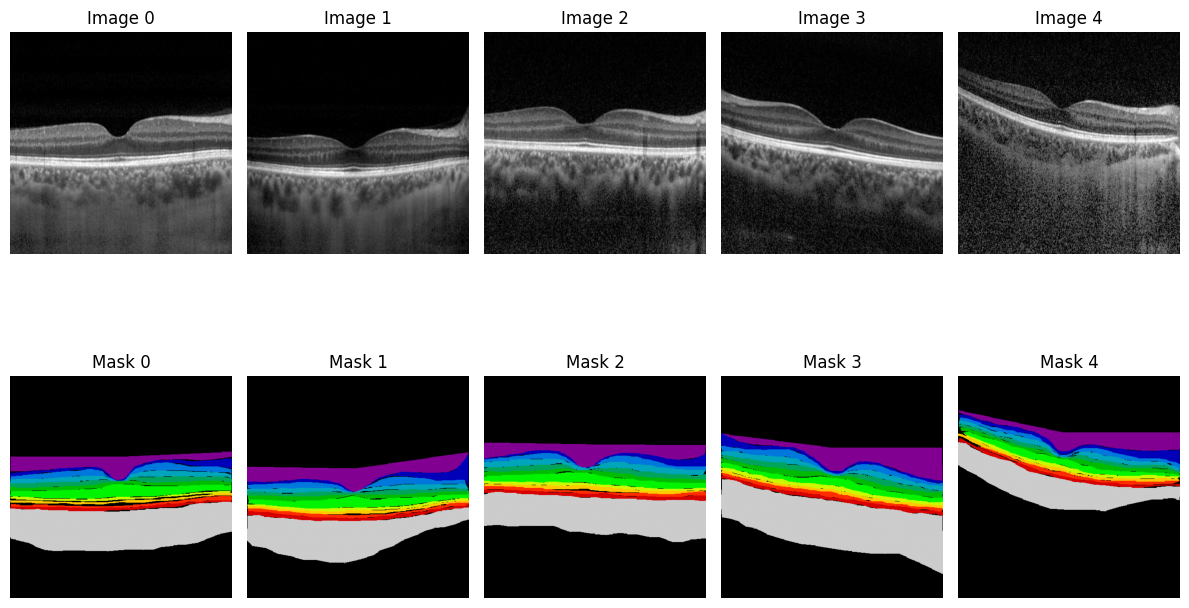

In [7]:
plt.figure(figsize=(12, 8))
for i in range(min(5, len(train_images))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title(f'Image {i}')
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(train_masks[i], cmap='nipy_spectral', vmin=0, vmax=n_classes - 1)
    plt.title(f'Mask {i}')
    plt.axis('off')

plt.tight_layout()
plt.show()


In [8]:
train_images = train_images.astype(np.float32)

if train_images.max() > 255:
    train_images /= 65535.0
else:
    train_images /= 255.0

train_images = np.expand_dims(train_images, axis=-1)
train_masks_input = np.expand_dims(train_masks.astype(np.uint8), axis=-1)

print('After prep: images', train_images.shape, train_images.dtype)
print('After prep: masks ', train_masks_input.shape, train_masks_input.dtype)
print('Classes in masks:', np.unique(train_masks_input))


After prep: images (50, 496, 496, 1) float32
After prep: masks  (50, 496, 496, 1) uint8
Classes in masks: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [9]:
indices = np.arange(len(train_images))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=seed,
    shuffle=True,
)

train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    random_state=seed,
    shuffle=True,
)

X_train = train_images[train_idx]
X_val = train_images[val_idx]
X_test = train_images[test_idx]

y_train = train_masks_input[train_idx]
y_val = train_masks_input[val_idx]
y_test = train_masks_input[test_idx]

print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_val:  ', X_val.shape, 'y_val:  ', y_val.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)


X_train: (36, 496, 496, 1) y_train: (36, 496, 496, 1)
X_val:   (9, 496, 496, 1) y_val:   (9, 496, 496, 1)
X_test:  (5, 496, 496, 1) y_test:  (5, 496, 496, 1)


In [10]:
y_train_cat = to_categorical(np.squeeze(y_train, axis=-1), num_classes=n_classes).astype(np.float32)
y_val_cat = to_categorical(np.squeeze(y_val, axis=-1), num_classes=n_classes).astype(np.float32)
y_test_cat = to_categorical(np.squeeze(y_test, axis=-1), num_classes=n_classes).astype(np.float32)

print('y_train_cat:', y_train_cat.shape)
print('y_val_cat:  ', y_val_cat.shape)
print('y_test_cat: ', y_test_cat.shape)


y_train_cat: (36, 496, 496, 13)
y_val_cat:   (9, 496, 496, 13)
y_test_cat:  (5, 496, 496, 13)


In [11]:
import importlib
import simple_unet

importlib.reload(simple_unet)

from simple_unet import enhanced_unet

model = enhanced_unet(
    n_classes=n_classes,
    IMG_HEIGHT=SIZE_X,
    IMG_WIDTH=SIZE_Y,
    IMG_CHANNELS=1,
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=['accuracy'],
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 496, 496,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 496, 496,  │        137 │ input_layer[0][0] │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 496, 496,  │        128 │ separable_conv2d… │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 496, 496,  │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 496, 496,  │      4,736 │ activation[0][0]  │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 496, 496,  │        128 │ separable_conv2d… │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 496, 496,  │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d   │ (None, 496, 496,  │          0 │ activation_1[0][… │
│ (SpatialDropout2D)  │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ spatial_dropout2… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 1, 1, 4)   │        260 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 1, 1, 64)  │        320 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 496, 496,  │          0 │ spatial_dropout2… │
│                     │ 64)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 496, 496,  │         65 │ multiply[0][0]    │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 496, 496,  │          0 │ multiply[0][0],   │
│ (Multiply)          │ 64)               │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 496, 496,  │        128 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 496, 496,  │          0 │ multiply_1[0][0], │
│                     │ 64)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 496, 496,  │          0 │ add[0][0]       

 Total params: 9,913,082 (37.82 MB)

 Trainable params: 9,913,082 (37.82 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    ModelCheckpoint(
        'complex_unet_edi_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1,
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1,
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1,
    ),
    CSVLogger('training_log_edi.csv', append=False),
]


In [13]:
history = model.fit(
    X_train,
    y_train_cat,
    batch_size=8,
    epochs=100,
    verbose=1,
    validation_data=(X_val, y_val_cat),
    shuffle=True,
    callbacks=callbacks,
)


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31s/step - accuracy: 0.1156 - loss: 2.3208 
Epoch 1: val_loss improved from None to 2.29755, saving model to complex_unet_edi_best.keras

Epoch 1: finished saving model to complex_unet_edi_best.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 189s 33s/step - accuracy: 0.1293 - loss: 2.3199 - val_accuracy: 0.2359 - val_loss: 2.2976 - learning_rate: 1.0000e-04
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31s/step - accuracy: 0.2502 - loss: 2.2707 
Epoch 2: val_loss improved from 2.29755 to 2.25303, saving model to complex_unet_edi_best.keras

Epoch 2: finished saving model to complex_unet_edi_best.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 166s 32s/step - accuracy: 0.2696 - loss: 2.2727 - val_accuracy: 0.3604 - val_loss: 2.2530 - learning_rate: 1.0000e-04
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31s/step - accuracy: 0.3666 - loss: 2.2277 
Epoch 3: val_loss improved from 2.25303 to 2.20031, saving model to complex_unet_edi_best.keras

Epoch 3: finished saving model to complex_unet_edi

In [14]:
model.save('complex_unet_edi_last.keras')
print('Saved final model to complex_unet_edi_last.keras')


Saved final model to complex_unet_edi_last.keras


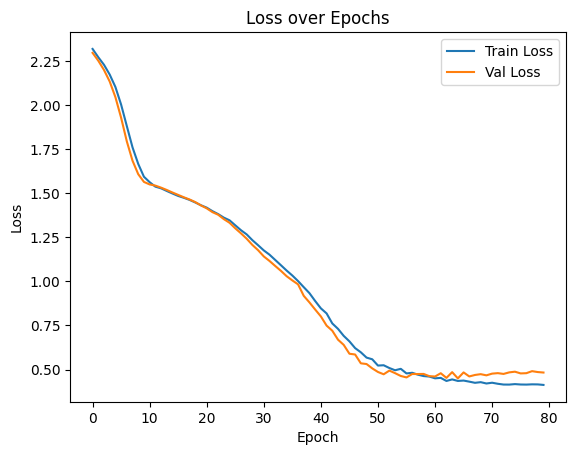

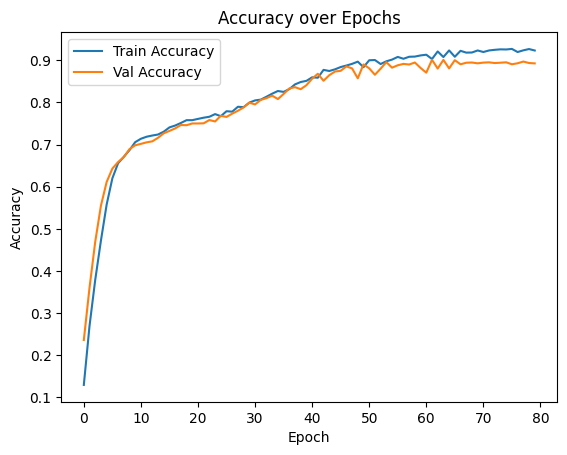

In [15]:
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss over Epochs')
plt.show()

plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy over Epochs')
plt.show()


In [16]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f'Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc * 100:.2f}%')

main_pred = model.predict(X_test, verbose=1)
y_pred = np.argmax(main_pred, axis=-1)
y_true = np.argmax(y_test_cat, axis=-1)

miou = MeanIoU(num_classes=n_classes)
miou.update_state(y_true, y_pred)
print('Mean IoU:', miou.result().numpy())


def dice_for_class(y_true, y_pred, cls_id, eps=1e-7):
    target = y_true == cls_id
    pred = y_pred == cls_id
    intersection = np.logical_and(target, pred).sum()
    denominator = target.sum() + pred.sum()
    return (2.0 * intersection + eps) / (denominator + eps)


for cls_id, cls_name in class_names.items():
    if cls_id == 0:
        continue
    print(f'{cls_name:18s} Dice: {dice_for_class(y_true, y_pred, cls_id):.4f}')


Test Loss: 0.5309 | Test Accuracy: 84.74%
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Mean IoU: 0.62238795
VITREUS            Dice: 0.7327
RNFL               Dice: 0.6392
GCL                Dice: 0.7091
IPL                Dice: 0.6854
INL                Dice: 0.7885
OPL                Dice: 0.7557
ONL                Dice: 0.8788
ELM                Dice: 0.8037
EZ                 Dice: 0.7763
IZ                 Dice: 0.7575
RPE                Dice: 0.7527
CHORIOCAPILLARIS   Dice: 0.7326


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


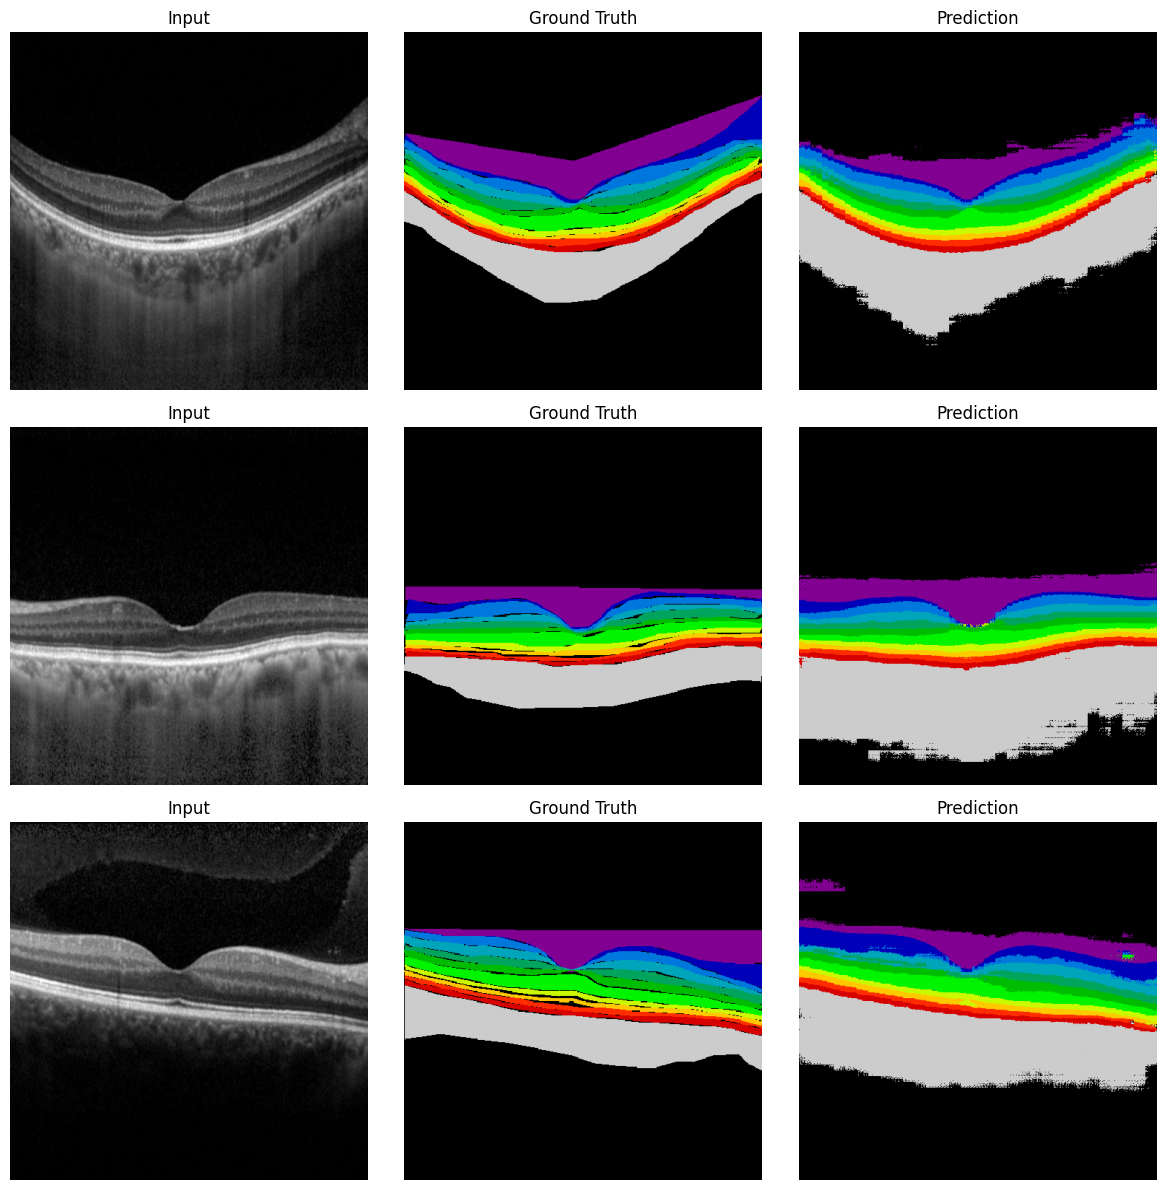

In [17]:
idx = np.random.choice(len(X_test), size=min(3, len(X_test)), replace=False)
preds = model.predict(X_test[idx], verbose=1)
pred_masks = np.argmax(preds, axis=-1)
true_masks = np.squeeze(y_test[idx], axis=-1)

fig, axes = plt.subplots(len(idx), 3, figsize=(12, 4 * len(idx)))
if len(idx) == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(len(idx)):
    axes[i, 0].imshow(X_test[idx[i]].squeeze(), cmap='gray')
    axes[i, 0].set_title('Input')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_masks[i], cmap='nipy_spectral', vmin=0, vmax=n_classes - 1)
    axes[i, 1].set_title('Ground Truth')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_masks[i], cmap='nipy_spectral', vmin=0, vmax=n_classes - 1)
    axes[i, 2].set_title('Prediction')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()
